
# Ghostbuster 1000 → 708 Eligibility Audit

This notebook audits the selection induced by the 384-scorer-token eligibility requirement used in the corrected seven-way Ghostbuster essay analysis.

The goals are to determine:

1. whether the 292 excluded source groups are excluded primarily because their essays are shorter;
2. whether exclusion is concentrated in particular generator streams;
3. whether the retained 708 groups differ materially from the full 1,000-group corpus in observable length characteristics;
4. whether the headline matched context-utility result is being estimated on a sharply selected tail of the corpus.

The audit is descriptive. It does **not** change the frozen eligibility rule used in the paper.


In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve repository locations robustly whether this notebook is launched
# from reproduction/, reproduction/experiments/, or the parent project.
HERE = Path.cwd().resolve()

candidates = [
    HERE,
    HERE.parent,
    HERE.parent.parent,
]

REPRO_ROOT = None
for p in candidates:
    if (p / "data" / "raw" / "ghostbuster_essays.parquet").exists():
        REPRO_ROOT = p
        break
    if (p / "reproduction" / "data" / "raw" / "ghostbuster_essays.parquet").exists():
        REPRO_ROOT = p / "reproduction"
        break

if REPRO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate reproduction/data/raw/ghostbuster_essays.parquet"
    )

RAW_PATH = REPRO_ROOT / "data" / "raw" / "ghostbuster_essays.parquet"
CTX_PATH = REPRO_ROOT / "results" / "ghostbuster_essay_context.parquet"
OUT_DIR = REPRO_ROOT / "results"
FIG_DIR = REPRO_ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("REPRO_ROOT:", REPRO_ROOT)
print("RAW_PATH:", RAW_PATH)
print("CTX_PATH:", CTX_PATH)


REPRO_ROOT: ..
RAW_PATH: ../data/raw/ghostbuster_essays.parquet
CTX_PATH: ../results/ghostbuster_essay_context.parquet


In [2]:

raw = pd.read_parquet(RAW_PATH)
ctx = pd.read_parquet(CTX_PATH)

print("raw shape:", raw.shape)
print("ctx shape:", ctx.shape)
print("\nraw columns:")
print(raw.columns.tolist())
print("\nctx columns:")
print(ctx.columns.tolist())


raw shape: (7000, 8)
ctx shape: (7000, 15)

raw columns:
['row_id', 'file', 'domain', 'generator', 'label', 'group_id', 'text', 'text_sha256']

ctx columns:
['row_id', 'eligible_384', 'n_scorer_tokens', 'n_targets', 'context_l_8', 'context_l_16', 'context_l_32', 'context_l_64', 'context_l_128', 'context_l_256', 'context_u_16', 'context_u_32', 'context_u_64', 'context_u_128', 'context_u_256']



## 1. Resolve identifiers, generator labels, eligibility, and scorer-token length

The corrected essay table should contain exactly 1,000 source groups × 7 streams.  
The context table should contain the same 7,000 documents plus the eligibility information used by `01_context_observational.ipynb`.

The code below is intentionally tolerant of small column-name differences.


In [3]:

def pick_col(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"None of {candidates} found in columns: {df.columns.tolist()}")
    return None

group_col_raw = pick_col(raw, ["group_id", "source_id", "essay_id", "original_id"])
gen_col_raw = pick_col(raw, ["generator", "source", "model", "label"])
text_col = pick_col(raw, ["text", "document", "content"])
row_col_raw = pick_col(raw, ["row_id", "id", "doc_id"], required=False)

# 00e output is row-oriented and may intentionally omit group/generator metadata.
group_col_ctx = pick_col(ctx, ["group_id", "source_id", "essay_id", "original_id"], required=False)
gen_col_ctx = pick_col(ctx, ["generator", "source", "model", "label"], required=False)
row_col_ctx = pick_col(ctx, ["row_id", "id", "doc_id"], required=False)

elig_col = pick_col(
    ctx,
    ["eligible_384", "eligible", "context_eligible", "is_eligible", "eligible_context"],
    required=False,
)

tok_col = pick_col(
    ctx,
    [
        "n_scorer_tokens", "n_tokens", "token_count", "scorer_tokens",
        "prefix_token_count", "num_tokens", "length_tokens"
    ],
    required=False,
)

print("raw group:", group_col_raw)
print("raw generator:", gen_col_raw)
print("raw row id:", row_col_raw)
print("ctx group:", group_col_ctx)
print("ctx generator:", gen_col_ctx)
print("ctx row id:", row_col_ctx)
print("eligibility:", elig_col)
print("token length:", tok_col)
print("text:", text_col)

if group_col_ctx is None or gen_col_ctx is None:
    if row_col_raw is None or row_col_ctx is None:
        raise KeyError(
            "Context table lacks group/generator metadata, so a shared row_id is required "
            "to join it back to the raw Ghostbuster table."
        )
    print("\nUsing row_id to join 00e context output back to raw metadata.")


raw group: group_id
raw generator: generator
raw row id: row_id
ctx group: None
ctx generator: None
ctx row id: row_id
eligibility: eligible_384
token length: n_scorer_tokens
text: text

Using row_id to join 00e context output back to raw metadata.


In [4]:

# Build one audit row per document from the raw seven-way corpus.
audit = raw[[group_col_raw, gen_col_raw, text_col] + ([row_col_raw] if row_col_raw else [])].copy()
rename_raw = {
    group_col_raw: "group_id",
    gen_col_raw: "generator",
    text_col: "text",
}
if row_col_raw:
    rename_raw[row_col_raw] = "row_id"
audit = audit.rename(columns=rename_raw)

# Bring in the 00e eligibility/token metadata.
ctx_keep = []
rename_ctx = {}

if group_col_ctx is not None and gen_col_ctx is not None:
    ctx_keep += [group_col_ctx, gen_col_ctx]
    rename_ctx[group_col_ctx] = "group_id"
    rename_ctx[gen_col_ctx] = "generator"
    merge_on = ["group_id", "generator"]
else:
    ctx_keep += [row_col_ctx]
    rename_ctx[row_col_ctx] = "row_id"
    merge_on = ["row_id"]

if elig_col is not None:
    ctx_keep.append(elig_col)
if tok_col is not None:
    ctx_keep.append(tok_col)

ctx_small = ctx[ctx_keep].copy().rename(columns=rename_ctx)

audit = audit.merge(
    ctx_small,
    on=merge_on,
    how="left",
    validate="one_to_one",
)

audit["char_len"] = audit["text"].str.len()
audit["word_len"] = audit["text"].str.split().str.len()

if elig_col is not None:
    audit["eligible_doc"] = audit[elig_col].fillna(False).astype(bool)
elif tok_col is not None:
    audit["eligible_doc"] = pd.to_numeric(audit[tok_col], errors="coerce").ge(384)
else:
    raise KeyError(
        "Could not infer eligibility: 00e result has neither an eligibility column "
        "nor a scorer-token-count column."
    )

print("audit shape:", audit.shape)
print("missing context matches:", int(audit[ctx_keep[-1]].isna().sum()) if ctx_keep else "n/a")
display(audit.head())


audit shape: (7000, 9)
missing context matches: 0


,group_id,generator,text,row_id,eligible_384,n_scorer_tokens,char_len,word_len,eligible_doc
0,1,human,The world has been shattered by Russia’s attac...,essay::human::1,False,364,1784,290,False
1,1,gpt,"Introduction:\nThe film ""12 Years a Slave"" ser...",essay::gpt::1,True,742,4184,586,True
2,1,claude,Social class had a profound influence on how w...,essay::claude::1,True,539,3029,454,True
3,1,gpt_prompt1,Introduction:\nThe film 12 Years a Slave delve...,essay::gpt_prompt1::1,True,716,4065,572,True
4,1,gpt_prompt2,Introduction:\nThe film 12 Years a Slave serve...,essay::gpt_prompt2::1,True,715,3997,553,True



### Optional token-count recovery

If the saved context table already contains scorer-token lengths, the notebook uses them directly.  
If not, the next cell reconstructs exact Qwen3-0.6B-Base token counts. This may require that the tokenizer is already cached locally.


In [5]:

if tok_col is not None:
    audit["scorer_token_len"] = pd.to_numeric(audit[tok_col], errors="coerce")
    print("Using saved scorer token lengths from:", tok_col)
else:
    from transformers import AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(
        "Qwen/Qwen3-0.6B-Base",
        use_fast=True,
    )
    audit["scorer_token_len"] = [
        len(tokenizer(t, add_special_tokens=False)["input_ids"])
        for t in audit["text"].tolist()
    ]
    print("Recomputed scorer-token lengths with Qwen/Qwen3-0.6B-Base.")

# Exact frozen rule used by the paper.
audit["eligible_by_384"] = audit["scorer_token_len"] >= 384

# Diagnose any mismatch with saved eligibility.
mismatch = (audit["eligible_doc"] != audit["eligible_by_384"]).sum()
print("eligibility mismatches vs >=384:", mismatch)

if mismatch:
    display(
        audit.loc[
            audit["eligible_doc"] != audit["eligible_by_384"],
            ["group_id", "generator", "scorer_token_len", "eligible_doc", "eligible_by_384"]
        ].head(20)
    )


Using saved scorer token lengths from: n_scorer_tokens
eligibility mismatches vs >=384: 0



## 2. Reconstruct complete-group eligibility

A source group enters the headline Ghostbuster analysis only if **all seven** associated texts are eligible.


In [6]:

expected_generators = {
    "human",
    "gpt",
    "claude",
    "gpt_prompt1",
    "gpt_prompt2",
    "gpt_semantic",
    "gpt_writing",
}

print("generators found:", sorted(audit["generator"].unique()))
print("n groups:", audit["group_id"].nunique())
print("rows per group distribution:")
display(audit.groupby("group_id").size().value_counts().sort_index())

group_summary = (
    audit.groupby("group_id")
    .agg(
        n_docs=("generator", "size"),
        n_eligible=("eligible_by_384", "sum"),
        min_token_len=("scorer_token_len", "min"),
        mean_token_len=("scorer_token_len", "mean"),
        max_token_len=("scorer_token_len", "max"),
        min_word_len=("word_len", "min"),
        mean_word_len=("word_len", "mean"),
    )
    .reset_index()
)

group_summary["complete_7way"] = group_summary["n_docs"].eq(7)
group_summary["eligible_group"] = (
    group_summary["complete_7way"] &
    group_summary["n_eligible"].eq(7)
)

print("Complete 7-way groups:", int(group_summary["complete_7way"].sum()))
print("Eligible 7-way groups:", int(group_summary["eligible_group"].sum()))
print("Excluded 7-way groups:", int((group_summary["complete_7way"] & ~group_summary["eligible_group"]).sum()))


generators found: ['claude', 'gpt', 'gpt_prompt1', 'gpt_prompt2', 'gpt_semantic', 'gpt_writing', 'human']
n groups: 1000
rows per group distribution:


7    1000
Name: count, dtype: int64

Complete 7-way groups: 1000
Eligible 7-way groups: 708
Excluded 7-way groups: 292



Expected headline check:

- full source groups: **1,000**
- complete eligible source groups: **708**
- excluded source groups: **292**

If these counts do not reproduce exactly, stop and inspect the upstream files before interpreting the audit.


In [7]:

assert audit["group_id"].nunique() == 1000, "Expected exactly 1,000 Ghostbuster source groups."
assert group_summary["complete_7way"].sum() == 1000, "Expected all source groups to contain seven streams."
assert group_summary["eligible_group"].sum() == 708, (
    f"Expected 708 complete eligible groups, got {group_summary['eligible_group'].sum()}."
)
print("PASS: exact 1000 → 708 group selection reproduced.")


PASS: exact 1000 → 708 group selection reproduced.



## 3. Which streams cause exclusion?


In [8]:

stream_summary = (
    audit.groupby("generator")
    .agg(
        n=("group_id", "size"),
        eligible=("eligible_by_384", "sum"),
        mean_tokens=("scorer_token_len", "mean"),
        median_tokens=("scorer_token_len", "median"),
        p10_tokens=("scorer_token_len", lambda s: s.quantile(0.10)),
        p25_tokens=("scorer_token_len", lambda s: s.quantile(0.25)),
    )
)
stream_summary["ineligible"] = stream_summary["n"] - stream_summary["eligible"]
stream_summary["ineligible_rate"] = stream_summary["ineligible"] / stream_summary["n"]
stream_summary = stream_summary.sort_values("ineligible_rate", ascending=False)

display(stream_summary)


,n,eligible,mean_tokens,median_tokens,p10_tokens,p25_tokens,ineligible,ineligible_rate
generator,,,,,,,,
human,1000,773,825.419,645.5,350.0,393.00,227,0.227
gpt,1000,970,688.027,680.0,443.9,510.00,30,0.030
gpt_semantic,1000,971,641.965,626.5,434.0,495.75,29,0.029
gpt_prompt1,1000,973,638.577,632.0,455.0,519.00,27,0.027
claude,1000,975,557.458,544.0,444.0,492.00,25,0.025
gpt_prompt2,1000,983,624.905,620.0,479.9,539.75,17,0.017
gpt_writing,1000,999,689.754,677.0,578.0,624.75,1,0.001


In [9]:

# Count how often each stream is the reason a group fails.
fail = audit.loc[~audit["eligible_by_384"]].copy()

fail_counts = (
    fail.groupby("generator")
    .size()
    .rename("n_ineligible_documents")
    .sort_values(ascending=False)
    .to_frame()
)
fail_counts["share_of_all_ineligible_docs"] = (
    fail_counts["n_ineligible_documents"] / fail_counts["n_ineligible_documents"].sum()
)
display(fail_counts)

# How many streams fail within each excluded group?
failed_per_group = (
    fail.groupby("group_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("n_failed_streams")
    .rename("n_groups")
)
display(failed_per_group.to_frame())


,n_ineligible_documents,share_of_all_ineligible_docs
generator,,
human,227,0.637640
gpt,30,0.084270
gpt_semantic,29,0.081461
gpt_prompt1,27,0.075843
claude,25,0.070225
gpt_prompt2,17,0.047753
gpt_writing,1,0.002809


,n_groups
n_failed_streams,
1,249
2,26
3,13
4,4



## 4. Are excluded groups simply shorter?

We compare group-level minimum and mean lengths for retained versus excluded source groups.


In [10]:

group_summary["selection"] = np.where(
    group_summary["eligible_group"], "retained", "excluded"
)

length_summary = (
    group_summary.groupby("selection")
    .agg(
        n=("group_id", "size"),
        min_token_mean=("min_token_len", "mean"),
        min_token_median=("min_token_len", "median"),
        min_token_p25=("min_token_len", lambda s: s.quantile(.25)),
        min_token_p75=("min_token_len", lambda s: s.quantile(.75)),
        mean_token_mean=("mean_token_len", "mean"),
        mean_word_mean=("mean_word_len", "mean"),
    )
)
display(length_summary)


,n,min_token_mean,min_token_median,min_token_p25,min_token_p75,mean_token_mean,mean_word_mean
selection,,,,,,,
excluded,292,342.643836,353.0,330.00,367.0,594.181018,479.954501
retained,708,483.454802,471.0,427.75,524.0,696.448547,559.719532


In [11]:

# Nonparametric effect sizes / tests are descriptive here.
from scipy.stats import mannwhitneyu

ret = group_summary.loc[group_summary["eligible_group"], "mean_token_len"]
exc = group_summary.loc[~group_summary["eligible_group"], "mean_token_len"]

u = mannwhitneyu(ret, exc, alternative="two-sided")
print("Mann-Whitney U on group mean scorer-token length:")
print("statistic =", u.statistic)
print("p =", u.pvalue)

# Common-language effect: P(random retained group > random excluded group)
cl = u.statistic / (len(ret) * len(exc))
print("P(retained group longer than excluded group) ≈", cl)


Mann-Whitney U on group mean scorer-token length:
statistic = 153497.5
p = 1.497106171050525e-33
P(retained group longer than excluded group) ≈ 0.7424807483940872


../figures/ghostbuster_eligibility_group_length.pdf


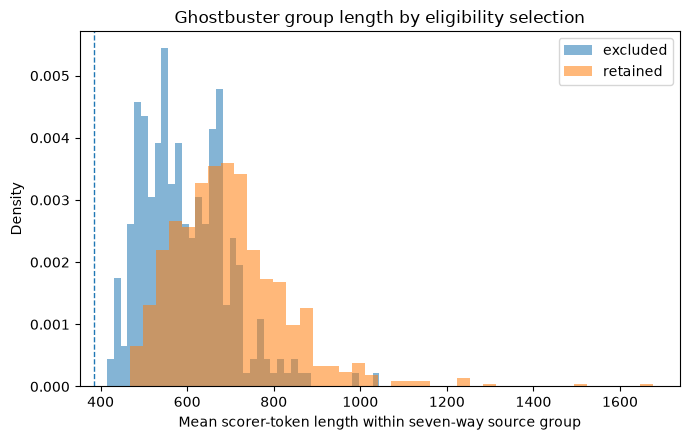

In [12]:

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, subset in group_summary.groupby("selection"):
    ax.hist(
        subset["mean_token_len"],
        bins=40,
        alpha=0.55,
        density=True,
        label=label,
    )
ax.axvline(384, linestyle="--", linewidth=1)
ax.set_xlabel("Mean scorer-token length within seven-way source group")
ax.set_ylabel("Density")
ax.set_title("Ghostbuster group length by eligibility selection")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "ghostbuster_eligibility_group_length.pdf"
fig.savefig(path, bbox_inches="tight")
print(path)
plt.show()



## 5. Generator-specific length shift induced by complete-case selection

Even if eligibility is fundamentally a length filter, requiring all seven streams to pass can change the retained length distribution for every generator. This table quantifies that shift.


In [13]:

selected_ids = set(
    group_summary.loc[group_summary["eligible_group"], "group_id"]
)

audit["group_selected"] = audit["group_id"].isin(selected_ids)

gen_shift = (
    audit.groupby(["generator", "group_selected"])
    .agg(
        n=("group_id", "size"),
        mean_tokens=("scorer_token_len", "mean"),
        median_tokens=("scorer_token_len", "median"),
        mean_words=("word_len", "mean"),
    )
    .reset_index()
)

pivot = gen_shift.pivot(index="generator", columns="group_selected")
display(pivot)


n       mean_tokens             median_tokens         \
group_selected False True        False       True          False  True    
generator                                                                 
claude           292   708  551.164384  560.053672         551.5  541.0   
gpt              292   708  646.770548  705.042373         599.0  702.5   
gpt_prompt1      292   708  598.236301  655.214689         587.0  645.0   
gpt_prompt2      292   708  594.167808  637.581921         583.5  627.0   
gpt_semantic     292   708  602.797945  658.118644         573.0  641.0   
gpt_writing      292   708  687.452055  690.703390         675.5  677.0   
human            292   708  478.678082  968.425141         362.0  729.5   

                mean_words              
group_selected       False       True   
generator                               
claude          448.280822  454.598870  
gpt             533.030822  578.809322  
gpt_prompt1     473.250000  515.228814  
gpt_prompt2     472.222603  507.560734  
gpt_semantic    501.496575  547.429379  
gpt_writing     544.517123  547.748588  
human           386.883562  766.661017


## 6. Sensitivity of the headline Ghostbuster result to the eligibility boundary

This is **not** a replacement analysis. It is a useful diagnostic if cached context utilities exist for documents near the threshold.

Because $U(256)$ requires target positions after 256 tokens and the frozen experiment uses a 384-token prefix, the primary analysis keeps the original 384-token requirement. We therefore do not redefine the headline sample here.

Instead, the most defensible audit question is whether the 708-group sample is predominantly a transparent length-selected subset rather than a generator-specific or otherwise irregular subset.



## 7. Save audit tables


In [14]:

audit_doc_path = OUT_DIR / "ghostbuster_eligibility_audit_documents.csv"
audit_group_path = OUT_DIR / "ghostbuster_eligibility_audit_groups.csv"
audit_stream_path = OUT_DIR / "ghostbuster_eligibility_audit_streams.csv"

audit.drop(columns=["text"]).to_csv(audit_doc_path, index=False)
group_summary.to_csv(audit_group_path, index=False)
stream_summary.reset_index().to_csv(audit_stream_path, index=False)

print(audit_doc_path)
print(audit_group_path)
print(audit_stream_path)


../results/ghostbuster_eligibility_audit_documents.csv
../results/ghostbuster_eligibility_audit_groups.csv
../results/ghostbuster_eligibility_audit_streams.csv



## 8. Automatic interpretation block

Run the cell below after the tables above. It prints a concise summary suitable for deciding whether the paper needs an additional limitation sentence.


In [15]:

retained = group_summary[group_summary["eligible_group"]]
excluded = group_summary[~group_summary["eligible_group"]]

worst_stream = stream_summary.index[0]
worst_rate = stream_summary.iloc[0]["ineligible_rate"]
best_rate = stream_summary.iloc[-1]["ineligible_rate"]

print("ELIGIBILITY AUDIT SUMMARY")
print("-------------------------")
print(f"Groups retained: {len(retained)} / {len(group_summary)} ({len(retained)/len(group_summary):.1%})")
print(f"Groups excluded: {len(excluded)} / {len(group_summary)} ({len(excluded)/len(group_summary):.1%})")
print()
print(f"Mean group scorer-token length:")
print(f"  retained = {retained['mean_token_len'].mean():.1f}")
print(f"  excluded = {excluded['mean_token_len'].mean():.1f}")
print(f"Common-language P(retained > excluded) = {cl:.3f}")
print()
print("Generator-specific ineligibility rates:")
for g, row in stream_summary.iterrows():
    print(f"  {g:14s} {row['ineligible_rate']:.1%} ({int(row['ineligible'])}/{int(row['n'])})")
print()
print(f"Rate spread across streams: {worst_rate - best_rate:.1%}")

if (worst_rate - best_rate) < 0.10 and cl > 0.80:
    print("\nInterpretation: selection is predominantly a document-length effect,")
    print("with relatively limited generator-specific imbalance.")
else:
    print("\nInterpretation: inspect the stream-level imbalance before describing")
    print("the excluded groups as merely shorter.")


ELIGIBILITY AUDIT SUMMARY
-------------------------
Groups retained: 708 / 1000 (70.8%)
Groups excluded: 292 / 1000 (29.2%)

Mean group scorer-token length:
  retained = 696.4
  excluded = 594.2
Common-language P(retained > excluded) = 0.742

Generator-specific ineligibility rates:
  human          22.7% (227/1000)
  gpt            3.0% (30/1000)
  gpt_semantic   2.9% (29/1000)
  gpt_prompt1    2.7% (27/1000)
  claude         2.5% (25/1000)
  gpt_prompt2    1.7% (17/1000)
  gpt_writing    0.1% (1/1000)

Rate spread across streams: 22.6%

Interpretation: inspect the stream-level imbalance before describing
the excluded groups as merely shorter.
